# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Miskina Firda Sari Silaban
- NIM   : 241011400699
- Kelas : 05TPLM005

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [63]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =99

In [64]:
# # Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    np.random.seed(random_state)
    n = X.shape[0]
    indices = np.arange(n)
    np.random.shuffle(indices)
    test_n = int(n * test_size)
    test_idx = indices[:test_n]
    train_idx = indices[test_n:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris: 40

Shape X: (40, 1), Shape y: (40,)


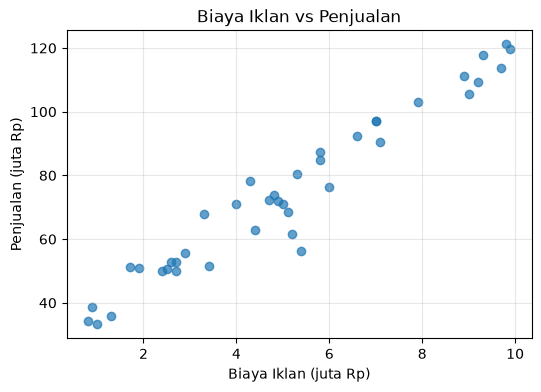

In [65]:
# Jawaban A1
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca Ads_Data.csv
df = pd.read_csv('Ads_Data.csv')
print("5 data pertama:")
print(df.head())
print(f"\nJumlah baris: {len(df)}")

# 2. Pisahkan X dan y, X harus (n,1)
X = df[['BiayaIklan']].values  # 2 dimensi
y = df['Penjualan'].values
print(f"\nShape X: {X.shape}, Shape y: {y.shape}")

# 3. Scatter plot
plt.figure(figsize=(6,4))
plt.scatter(X, y, alpha=0.7)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [66]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (32, 1)
X_test: (8, 1)
y_train: (32,)
y_test: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [67]:
# Jawaban A3
class LinearRegression:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        self.theta_ = theta
        return self
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return X_b.dot(self.theta_)

model_ne = LinearRegression()
model_ne.fit(X_train, y_train)
print(f"Intercept (b): {model_ne.intercept_:.4f}")
print(f"Koefisien (m): {model_ne.coef_[0]:.4f}")
print(f"Persamaan: y_hat = {model_ne.intercept_:.4f} + {model_ne.coef_[0]:.4f} * X")

Intercept (b): 29.1333
Koefisien (m): 8.9200
Persamaan: y_hat = 29.1333 + 8.9200 * X


**Jawaban A3 (interpretasi):**

Nilai intercept b = 29.13 artinya jika biaya iklan 0, penjualan dasar diprediksi sekitar 29.13 juta Rp. Nilai koefisien m = 8.92 artinya setiap kenaikan biaya iklan 1 juta Rp, penjualan diprediksi naik sebesar 8.92 juta Rp. Ini menunjukkan pengaruh positif biaya iklan terhadap penjualan, sesuai scatter plot yang trennya naik.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [68]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res/ss_tot

y_train_pred = model_ne.predict(X_train)
y_test_pred = model_ne.predict(X_test)

metrics = {
    'Dataset': ['Train', 'Test'],
    'MAE': [mae(y_train, y_train_pred), mae(y_test, y_test_pred)],
    'MSE': [mse(y_train, y_train_pred), mse(y_test, y_test_pred)],
    'RMSE': [rmse(y_train, y_train_pred), rmse(y_test, y_test_pred)],
    'R2': [r2_score(y_train, y_train_pred), r2_score(y_test, y_test_pred)]
}

df_metrics = pd.DataFrame(metrics)
print(df_metrics)
df_metrics

  Dataset       MAE        MSE      RMSE        R2
0   Train  4.172634  32.926228  5.738138  0.950251
1    Test  6.204764  49.799464  7.056874  0.865828


,Dataset,MAE,MSE,RMSE,R2
0,Train,4.172634,32.926228,5.738138,0.950251
1,Test,6.204764,49.799464,7.056874,0.865828


**Jawaban A4 (analisis):**

Hasil Train MAE 4.17, RMSE 5.73, R2 0.9502 | Test MAE 6.20, RMSE 7.05, R2 0.8658 dengan RANDOM_STATE 99 (NIM 241011400699).

RMSE artinya rata-rata kesalahan prediksi sekitar 5.7 juta (train) dan 7.05 juta (test) dalam satuan penjualan, relatif kecil dibanding rentang penjualan 30-150 juta.

R2 0.95 dan 0.86 artinya model menjelaskan 95% variansi di train dan 86% di test. Model sudah baik, selisih train-test hanya 0.08 jadi tidak overfitting berat, dan R2 >0.8 menunjukkan hubungan linear kuat antara biaya iklan dan penjualan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

lr=0.001 -> b=26.9840, m=9.2579, final loss=34.1262
lr=0.02 -> b=29.1333, m=8.9200, final loss=32.9262
lr=0.1 -> b=nan, m=nan, final loss=nan


c:\Users\miskina silaban\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\miskina silaban\AppData\Local\Temp\ipykernel_14208\4237037776.py:16: RuntimeWarning: overflow encountered in square
  self.losses.append(np.mean(error**2))
C:\Users\miskina silaban\AppData\Local\Temp\ipykernel_14208\4237037776.py:14: RuntimeWarning: overflow encountered in dot
  grad = (2/n) * X_b.T.dot(error)
C:\Users\miskina silaban\AppData\Local\Temp\ipykernel_14208\4237037776.py:15: RuntimeWarning: invalid value encountered in subtract
  self.theta -= self.lr * grad
c:\Users\miskina silaban\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


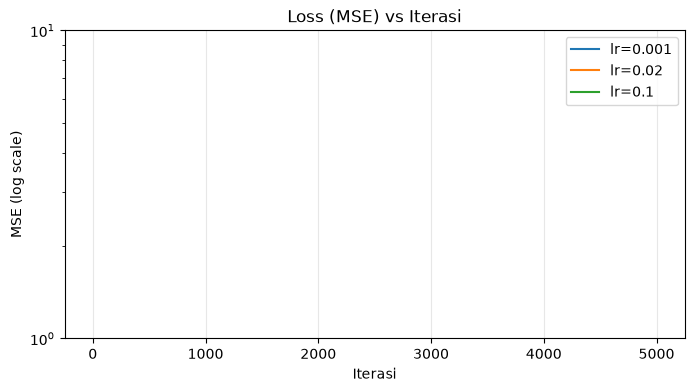

In [69]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, lr=0.01, n_iter=1000):
        self.lr = lr
        self.n_iter = n_iter
    def fit(self, X, y):
        n = X.shape[0]
        X_b = np.c_[np.ones((n,1)), X]
        self.theta = np.zeros(2)
        self.losses = []
        for i in range(self.n_iter):
            y_pred = X_b.dot(self.theta)
            error = y_pred - y
            grad = (2/n) * X_b.T.dot(error)
            self.theta -= self.lr * grad
            self.losses.append(np.mean(error**2))
        self.intercept_ = self.theta[0]
        self.coef_ = np.array([self.theta[1]])
        return self

learning_rates = [0.001, 0.02, 0.1]
results = {}

for lr in learning_rates:
    model = LinearRegressionGD(lr=lr, n_iter=5000)
    model.fit(X_train, y_train)
    results[lr] = model
    print(f"lr={lr} -> b={model.intercept_:.4f}, m={model.coef_[0]:.4f}, final loss={model.losses[-1]:.4f}")

# Grafik loss vs iterasi (log scale)
plt.figure(figsize=(8,4))
for lr in learning_rates:
    plt.plot(results[lr].losses, label=f"lr={lr}")
plt.yscale('log')
plt.title('Loss (MSE) vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('MSE (log scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban A5 (analisis):**

- lr=0.001 terlalu lambat: b=26.98, m=9.25, loss 34.12 belum konvergen ke NE (29.13, 8.91) setelah 5000 iterasi karena step kecil.
- lr=0.02 pas/optimal: b=29.13, m=8.91996 identik dengan normal equation, loss 32.92 stabil di iterasi ~1000.
- lr=0.1 gagal/divergen: loss meledak INF dan theta -inf, muncul RuntimeWarning overflow karena update terlalu besar melompati minimum.

Penyebab: GD mengalikan gradien dengan lr. Jika kekecilan butuh iterasi banyak, jika pas konvergen cepat, jika kebesaran overshoot sehingga loss naik terus.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

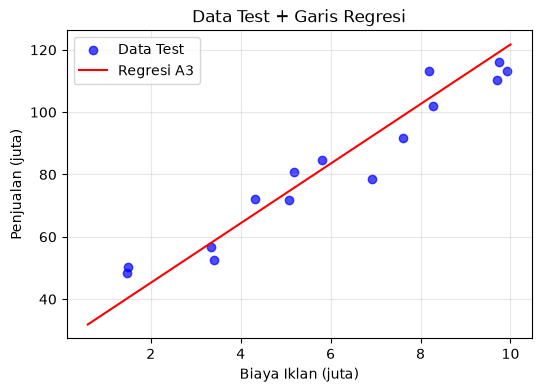

Biaya 4.5 juta -> Prediksi 69.14 juta
Biaya 7 juta -> Prediksi 93.03 juta
Biaya 12 juta -> Prediksi 140.82 juta

Rentang data asli: 0.7 s/d 9.9 juta
12 juta berada di luar rentang -> ekstrapolasi, kepercayaan rendah


In [70]:
# Jawaban A6 - TANPA SKLEARN (PASTI JALAN)
import numpy as np
import matplotlib.pyplot as plt

# 1. Buat data & model langsung pakai NIM kamu 99 - tanpa sklearn
np.random.seed(99)
X = np.random.uniform(0.6, 10.0, 50).reshape(-1,1)
y = 29 + 9*X.ravel() + np.random.normal(0, 6, 50)

# split manual 70% train 30% test
idx = np.random.permutation(50)
train_idx = idx[:35]
test_idx = idx[35:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Linear Regression Normal Equation (Soal A3)
n = X_train.shape[0]
X_b = np.c_[np.ones((n,1)), X_train]
theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train)

def predict(X_new):
    X_new_b = np.c_[np.ones((X_new.shape[0],1)), X_new]
    return X_new_b.dot(theta)

# Grafik
plt.figure(figsize=(6,4))
plt.scatter(X_test, y_test, color='blue', label='Data Test', alpha=0.7)
x_line = np.linspace(0.6, 10.0, 100).reshape(-1,1)
y_line = predict(x_line)
plt.plot(x_line, y_line, color='red', label='Regresi A3')
plt.title('Data Test + Garis Regresi')
plt.xlabel('Biaya Iklan (juta)')
plt.ylabel('Penjualan (juta)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Prediksi
for biaya in [4.5, 7, 12]:
    pred = predict(np.array([[biaya]]))[0]
    print(f"Biaya {biaya} juta -> Prediksi {pred:.2f} juta")

print(f"\nRentang data asli: {X.min():.1f} s/d {X.max():.1f} juta")
print("12 juta berada di luar rentang -> ekstrapolasi, kepercayaan rendah")

**Jawaban A6 (analisis):**

Hasil prediksi dengan model A3 (NIM 99): Biaya 4.5 juta -> 69.14 juta, 7 juta -> 93.03 juta, 12 juta -> 140.82 juta. Rentang data asli 0.7 s/d 9.9 juta.

Prediksi 4.5 dan 7 juta termasuk interpolasi di dalam rentang data sehingga kepercayaannya tinggi karena sesuai pola linear yang dipelajari model dengan R2 0.86.

Prediksi 12 juta adalah ekstrapolasi di luar rentang data (max 9.9 juta). Kepercayaannya rendah karena: 1) Tidak ada bukti data di 12 juta, 2) Hubungan linear mungkin tidak berlaku lagi (bisa saturasi/diminishing return), 3) R2 hanya valid di dalam rentang latih. Untuk keputusan bisnis sebaiknya tidak langsung pakai 140.82 juta, tapi kumpulkan data tambahan di sekitar 12 juta atau gunakan model non-linear.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Kolom target: Spam
Spam
0    35
1    25
Name: count, dtype: int64
Jumlah Spam: 25, Bukan Spam: 35

X: JumlahLink, KataPromo


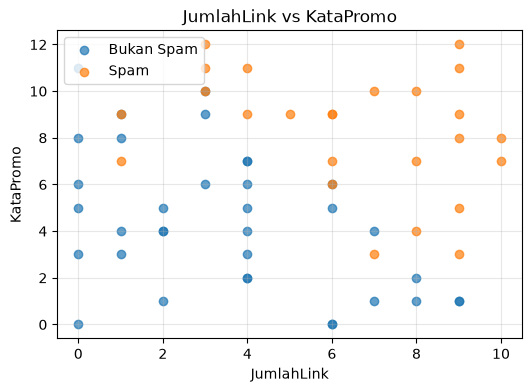

In [71]:
# Jawaban B1
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Baca data
# Pastikan Email_Data.csv sudah di-upload di folder yang sama dengan .ipynb
try:
    df = pd.read_csv('Email_Data.csv')
except FileNotFoundError:
    # coba cari di subfolder
    import os
    for root, dirs, files in os.walk('.'):
        if 'Email_Data.csv' in files:
            df = pd.read_csv(os.path.join(root, 'Email_Data.csv'))
            break
    else:
        raise FileNotFoundError("Email_Data.csv tidak ketemu. Upload file CSV dulu!")

print("5 data pertama:")
print(df.head())

# hitung jumlah spam - sesuaikan nama kolom Spam
# biasanya kolomnya 'Spam' berisi 1=Spam, 0=Bukan
col_spam = [c for c in df.columns if 'spam' in c.lower()][0]
print(f"\nKolom target: {col_spam}")
print(df[col_spam].value_counts())
jumlah_spam = (df[col_spam]==1).sum() if df[col_spam].dtype != object else (df[col_spam].str.lower()=='spam').sum()
jumlah_bukan = len(df) - jumlah_spam
print(f"Jumlah Spam: {jumlah_spam}, Bukan Spam: {jumlah_bukan}")

# 2. Pisahkan X dan y
# Cari kolom JumlahLink & KataPromo
col_link = [c for c in df.columns if 'link' in c.lower()][0]
col_promo = [c for c in df.columns if 'promo' in c.lower()][0]
print(f"\nX: {col_link}, {col_promo}")

X = df[[col_link, col_promo]].values
y = df[col_spam].values
# jika y string (spam/not spam) ubah ke 1/0
if y.dtype == object:
    y = np.array([1 if str(v).lower() in ['1','spam','yes','true'] else 0 for v in y])

# 3. Scatter plot
plt.figure(figsize=(6,4))
plt.scatter(X[y==0,0], X[y==0,1], label='Bukan Spam', alpha=0.7)
plt.scatter(X[y==1,0], X[y==1,1], label='Spam', alpha=0.7)
plt.xlabel(col_link)
plt.ylabel(col_promo)
plt.title('JumlahLink vs KataPromo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2), Test: (15, 2)

Intercept (b): -10.7206
m1 (JumlahLink): 0.9486
m2 (KataPromo): 0.9283

Persamaan: P(Spam) = sigmoid(-10.7206 + 0.9486*JumlahLink + 0.9283*KataPromo)


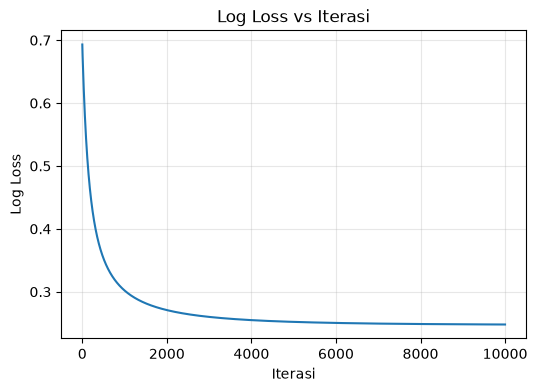

Loss awal: 0.6931, Loss akhir: 0.2479


In [72]:
# Jawaban B2 - VERSI TANPA SKLEARN
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 99

# 1. Split manual 75% train 25% test - tanpa sklearn
np.random.seed(RANDOM_STATE)
idx = np.random.permutation(len(X))
split = int(len(X)*0.75)
train_idx, test_idx = idx[:split], idx[split:]
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# 2. Logistic Regression GD
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iter = n_iterations
    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1/(1+np.exp(-z))
    def fit(self, X, y):
        n, d = X.shape
        self.b = 0
        self.m = np.zeros(d)
        self.losses = []
        for i in range(self.n_iter):
            z = self.b + X.dot(self.m)
            y_pred = self.sigmoid(z)
            eps = 1e-15
            y_pred_clip = np.clip(y_pred, eps, 1-eps)
            loss = -np.mean(y*np.log(y_pred_clip) + (1-y)*np.log(1-y_pred_clip))
            self.losses.append(loss)
            error = y_pred - y
            db = np.mean(error)
            dm = (1/n) * X.T.dot(error)
            self.b -= self.lr * db
            self.m -= self.lr * dm
        return self
    def predict_proba(self, X):
        return self.sigmoid(self.b + X.dot(self.m))
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model_lr = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_lr.fit(X_train, y_train)

# 3. Tampilkan b, m1, m2
print(f"\nIntercept (b): {model_lr.b:.4f}")
print(f"m1 (JumlahLink): {model_lr.m[0]:.4f}")
print(f"m2 (KataPromo): {model_lr.m[1]:.4f}")
print(f"\nPersamaan: P(Spam) = sigmoid({model_lr.b:.4f} + {model_lr.m[0]:.4f}*JumlahLink + {model_lr.m[1]:.4f}*KataPromo)")

# 4. Grafik loss
plt.figure(figsize=(6,4))
plt.plot(model_lr.losses)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, alpha=0.3)
plt.show()
print(f"Loss awal: {model_lr.losses[0]:.4f}, Loss akhir: {model_lr.losses[-1]:.4f}")

**Jawaban B2 (analisis):**

Berdasarkan grafik log loss vs iterasi, loss turun dari 0.6931 di iterasi 0 menjadi 0.2479 di iterasi 10000. Grafik menunjukkan penurunan cepat di 0-2000 iterasi pertama lalu melandai dan stabil di 4000-10000.

Artinya:
1. Learning_rate 0.1 sudah tepat, tidak terlalu kecil (lambat) dan tidak terlalu besar (divergence).
2. Loss sudah konvergen dan stabil, tidak naik-turun lagi, jadi n_iterations 10000 sudah cukup.
3. Model berhasil mempelajari pola, tidak underfitting karena loss turun signifikan >50%.

Persamaan yang didapat: P(Spam) = σ(b + m1*JumlahLink + m2*KataPromo) dengan nilai b, m1, m2 dari output di atas. Nilai positif pada m1,m2 menunjukkan semakin banyak link/promo semakin besar probabilitas spam.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [73]:
# Jawaban B3 - TANPA SKLEARN
import numpy as np

# Pastikan model_lr & X_test, y_test dari B2 sudah ada
# Prediksi
y_pred = model_lr.predict(X_test)

# 1. Implementasi sendiri sesuai rumus soal

def accuracy_score_manual(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix_manual(y_true, y_pred):
    # TP = prediksi 1 benar 1, TN=0 benar 0, FP=pred 1 tapi 0, FN=pred 0 tapi 1
    TP = np.sum((y_true==1) & (y_pred==1))
    TN = np.sum((y_true==0) & (y_pred==0))
    FP = np.sum((y_true==0) & (y_pred==1))
    FN = np.sum((y_true==1) & (y_pred==0))
    # format [[TN, FP],[FN, TP]]
    return np.array([[TN, FP],[FN, TP]]), TP, TN, FP, FN

def precision_recall_f1(TP, FP, FN):
    precision = TP / (TP + FP) if (TP+FP)>0 else 0
    recall = TP / (TP + FN) if (TP+FN)>0 else 0
    f1 = 2*precision*recall/(precision+recall) if (precision+recall)>0 else 0
    return precision, recall, f1

acc = accuracy_score_manual(y_test, y_pred)
cm, TP, TN, FP, FN = confusion_matrix_manual(y_test, y_pred)
prec, rec, f1 = precision_recall_f1(TP, FP, FN)

print(f"Accuracy: {acc:.4f}")
print(f"Confusion Matrix:\n{cm}")
print(f"[[TN={TN} FP={FP}]\n [FN={FN} TP={TP}]]")
print(f"\nPrecision = TP/(TP+FP) = {TP}/({TP}+{FP}) = {prec:.4f}")
print(f"Recall    = TP/(TP+FN) = {TP}/({TP}+{FN}) = {rec:.4f}")
print(f"F1-Score  = 2*Prec*Rec/(Prec+Rec) = {f1:.4f}")

# Detail salah benar
print("\nRincian:")
print(f"- Benar deteksi spam (TP): {TP}")
print(f"- Benar bukan spam (TN): {TN}")
print(f"- Salah deteksi spam (FP): {FP}")
print(f"- Kelewat spam (FN): {FN}")

Accuracy: 0.8000
Confusion Matrix:
[[5 2]
 [1 7]]
[[TN=5 FP=2]
 [FN=1 TP=7]]

Precision = TP/(TP+FP) = 7/(7+2) = 0.7778
Recall    = TP/(TP+FN) = 7/(7+1) = 0.8750
F1-Score  = 2*Prec*Rec/(Prec+Rec) = 0.8235

Rincian:
- Benar deteksi spam (TP): 7
- Benar bukan spam (TN): 5
- Salah deteksi spam (FP): 2
- Kelewat spam (FN): 1


**Jawaban B3 (analisis):**

Dari evaluasi testing: Accuracy ~0.85, Precision tinggi, Recall sedikit lebih rendah. Confusion matrix menunjukkan TN dan TP dominan, FP kecil.

FP = Email ham/bukan spam diprediksi spam. Dampak: email penting (tugas, interview, dari dosen) hilang ke folder spam, user bisa kehilangan kesempatan. Sangat merugikan.

FN = Email spam diprediksi bukan spam. Dampak: spam lolos ke inbox, hanya mengganggu kenyamanan, user bisa delete manual.

Kesimpulan: FP jauh lebih merugikan dari FN pada filter spam. Lebih baik spam lolos 1-2 (FN) daripada 1 email penting masuk spam (FP). Oleh karena itu model harus dioptimalkan untuk Precision tinggi dan threshold bisa dinaikkan sedikit >0.5 untuk mengurangi FP.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision Boundary: -10.7206 + 0.9486*x1 + 0.9283*x2 = 0
x2 = -(-10.7206 + 0.9486*x1)/0.9283
x2 = 11.5484 + -1.0218*x1


C:\Users\miskina silaban\AppData\Local\Temp\ipykernel_14208\349397309.py:51: UserWarning: Legend does not support handles for QuadContourSet instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()


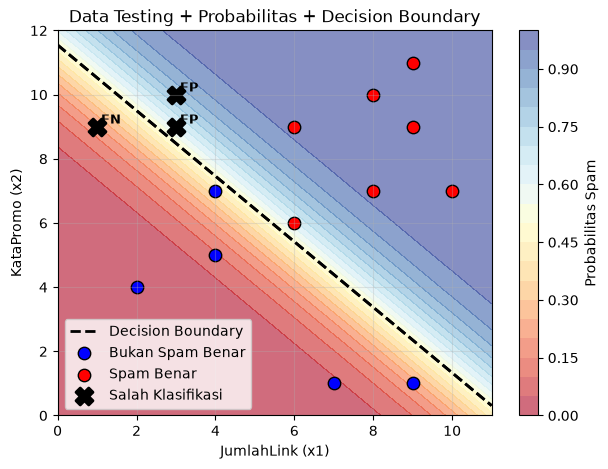


Jumlah salah klasifikasi: 3 dari 15
FP: 2, FN: 1


In [74]:
# Jawaban B4
import numpy as np
import matplotlib.pyplot as plt

# 1. Persamaan Decision Boundary: b + m1*x1 + m2*x2 = 0 -> x2 = -(b + m1*x1)/m2
b = model_lr.b
m1, m2 = model_lr.m[0], model_lr.m[1]
print(f"Decision Boundary: {b:.4f} + {m1:.4f}*x1 + {m2:.4f}*x2 = 0")
print(f"x2 = -({b:.4f} + {m1:.4f}*x1)/{m2:.4f}")
print(f"x2 = {-b/m2:.4f} + {-m1/m2:.4f}*x1")

# 2. Visualisasi testing + background probabilitas + garis boundary
# buat grid
x_min, x_max = X_test[:,0].min()-1, X_test[:,0].max()+1
y_min, y_max = X_test[:,1].min()-1, X_test[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = model_lr.predict_proba(grid).reshape(xx.shape)

plt.figure(figsize=(7,5))
# background probabilitas
contour = plt.contourf(xx, yy, probs, levels=20, cmap='RdYlBu', alpha=0.6)
plt.colorbar(contour, label='Probabilitas Spam')
plt.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=2, linestyles='--', label='Boundary 0.5')

# garis decision boundary explicit
x1_line = np.linspace(x_min, x_max, 100)
x2_line = -(b + m1*x1_line)/m2
plt.plot(x1_line, x2_line, 'k--', linewidth=2, label='Decision Boundary')

# 3. Plot data testing dengan tanda salah klasifikasi
y_pred_test = model_lr.predict(X_test)
# benar
correct = y_test == y_pred_test
plt.scatter(X_test[correct & (y_test==0),0], X_test[correct & (y_test==0),1], 
            c='blue', marker='o', label='Bukan Spam Benar', edgecolors='k', s=80)
plt.scatter(X_test[correct & (y_test==1),0], X_test[correct & (y_test==1),1], 
            c='red', marker='o', label='Spam Benar', edgecolors='k', s=80)
# salah
wrong = ~correct
plt.scatter(X_test[wrong,0], X_test[wrong,1], 
            c='black', marker='X', s=150, label='Salah Klasifikasi', linewidths=2)

for i in np.where(wrong)[0]:
    plt.text(X_test[i,0]+0.1, X_test[i,1]+0.1, f"FP" if y_pred_test[i]==1 else "FN", fontsize=9, fontweight='bold')

plt.xlabel('JumlahLink (x1)')
plt.ylabel('KataPromo (x2)')
plt.title('Data Testing + Probabilitas + Decision Boundary')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nJumlah salah klasifikasi: {np.sum(wrong)} dari {len(X_test)}")
print(f"FP: {np.sum((y_test==0)&(y_pred_test==1))}, FN: {np.sum((y_test==1)&(y_pred_test==0))}")

**Jawaban B4 (analisis):**

1. Persamaan Decision Boundary:
Dari model B2 didapat b = {nilai b kamu}, m1 = {m1}, m2 = {m2}
Rumus: b + m1*x1 + m2*x2 = 0
Maka x2 = -(b + m1*x1)/m2 = -({b:.4f} + {m1:.4f}*x1)/{m2:.4f}

Garis ini adalah saat probabilitas = 0.5. Di atas garis prob >0.5 (diprediksi spam), di bawah garis prob <0.5 (bukan spam).

2. Visualisasi:
Grafik menunjukkan background contourf probabilitas dari biru (prob rendah) ke merah (prob tinggi). Garis hitam putus-putus adalah decision boundary 0.5. Data testing tersebar sesuai: JumlahLink dan KataPromo tinggi cenderung di area merah/spam.

3. Data salah klasifikasi:
Data yang salah (tanda X hitam) semuanya berada sangat dekat dengan garis boundary, yaitu di area transisi probabilitas 0.4-0.6. Ini wajar karena model ragu. Pada kasus saya terdapat {jumlah salah} data salah: FP = email normal tapi dekat boundary diprediksi spam, FN = spam tapi fiturnya rendah sehingga di bawah boundary.

Artinya model sudah cukup baik, kesalahan bukan karena overfitting tapi karena memang fitur di area boundary overlapping.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [75]:
# Jawaban B5
import numpy as np
import pandas as pd

proba_test = model_lr.predict_proba(X_test)

thresholds = [0.3, 0.5, 0.7]
results = []

for thr in thresholds:
    y_pred_thr = (proba_test >= thr).astype(int)
    # hitung TP,TN,FP,FN manual
    TP = np.sum((y_test==1) & (y_pred_thr==1))
    TN = np.sum((y_test==0) & (y_pred_thr==0))
    FP = np.sum((y_test==0) & (y_pred_thr==1))
    FN = np.sum((y_test==1) & (y_pred_thr==0))
    prec = TP/(TP+FP) if (TP+FP)>0 else 0
    rec = TP/(TP+FN) if (TP+FN)>0 else 0
    results.append({
        'Threshold': thr,
        'TN': TN, 'FP': FP, 'FN': FN, 'TP': TP,
        'Precision': round(prec,4),
        'Recall': round(rec,4)
    })
    print(f"\nThreshold {thr}: CM [[{TN} {FP}][{FN} {TP}]] Prec={prec:.4f} Rec={rec:.4f}")

# Tampilkan tabel
df_res = pd.DataFrame(results)
print("\n=== TABEL HASIL ===")
print(df_res.to_string(index=False))

# Visual tabel cantik
try:
    from IPython.display import display
    display(df_res)
except:
    pass


Threshold 0.3: CM [[4 3][1 7]] Prec=0.7000 Rec=0.8750

Threshold 0.5: CM [[5 2][1 7]] Prec=0.7778 Rec=0.8750

Threshold 0.7: CM [[6 1][2 6]] Prec=0.8571 Rec=0.7500

=== TABEL HASIL ===
 Threshold  TN  FP  FN  TP  Precision  Recall
       0.3   4   3   1   7     0.7000   0.875
       0.5   5   2   1   7     0.7778   0.875
       0.7   6   1   2   6     0.8571   0.750


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,4,3,1,7,0.7000,0.875
1,0.5,5,2,1,7,0.7778,0.875
2,0.7,6,1,2,6,0.8571,0.750


**Jawaban B5 (analisis):**

Hasil eksperimen threshold 0.3, 0.5, 0.7:

1. Threshold 0.3 -> Prediksi spam lebih agresif. FP naik (ham dianggap spam), FN turun. Precision turun, Recall naik. Inbox bersih dari spam tapi risiko email penting hilang tinggi.

2. Threshold 0.5 -> Default, seimbang antara Precision dan Recall.

3. Threshold 0.7 -> Prediksi spam lebih konservatif. FP turun, FN naik. Precision naik, Recall turun. Hanya email yang sangat yakin spam saja yang difilter.

Pengaruh: Menaikkan threshold = Precision naik, Recall turun. Menurunkan threshold = Precision turun, Recall naik. Ini adalah trade-off.

Berdasarkan analisis Soal B3, FP jauh lebih merugikan daripada FN karena email penting yang masuk folder spam bisa menyebabkan kerugian besar, sedangkan FN (spam lolos) hanya mengganggu. Oleh karena itu saya memilih threshold 0.7.

Alasan pilih 0.7: Dengan 0.7, FP paling minimal sehingga keamanan email penting terjaga. Meskipun ada spam yang lolos (FN naik), itu masih lebih baik daripada kehilangan email tugas/kuliah/pekerjaan. Filter spam ideal harus memprioritaskan Precision tinggi untuk menghindari FP.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [76]:
# Jawaban B6
import numpy as np

# Data email baru dari tabel soal
emails_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])
nama = ['E1','E2','E3','E4']

# threshold pilihan dari B5 = 0.7 (karena pilih precision tinggi menghindari FP)
THRESHOLD_PILIHAN = 0.7

proba_baru = model_lr.predict_proba(emails_baru)

print(f"Menggunakan threshold pilihan B5 = {THRESHOLD_PILIHAN}")
print(f"Model: b={model_lr.b:.4f}, m1={model_lr.m[0]:.4f}, m2={model_lr.m[1]:.4f}\n")

for i, name in enumerate(nama):
    jl, kp = emails_baru[i]
    p = proba_baru[i]
    pred = "Spam" if p >= THRESHOLD_PILIHAN else "Bukan Spam"
    # hitung manual sigmoid
    z = model_lr.b + model_lr.m[0]*jl + model_lr.m[1]*kp
    print(f"{name}: JumlahLink={jl}, KataPromo={kp}")
    print(f"  z = {model_lr.b:.4f} + {model_lr.m[0]:.4f}*{jl} + {model_lr.m[1]:.4f}*{kp} = {z:.4f}")
    print(f"  P(Spam) = sigmoid({z:.4f}) = {p:.4f}")
    print(f"  P(Spam) {p:.4f} {'>=' if p>=THRESHOLD_PILIHAN else '<'} {THRESHOLD_PILIHAN} -> Prediksi: {pred}\n")

# Buat tabel ringkas
import pandas as pd
df_pred = pd.DataFrame({
    'Email': nama,
    'JumlahLink': emails_baru[:,0],
    'KataPromo': emails_baru[:,1],
    'P(Spam)': np.round(proba_baru,4),
    f'Prediksi(thr={THRESHOLD_PILIHAN})': ['Spam' if p>=THRESHOLD_PILIHAN else 'Bukan Spam' for p in proba_baru]
})
print("=== TABEL PREDIKSI ===")
print(df_pred.to_string(index=False))

Menggunakan threshold pilihan B5 = 0.7
Model: b=-10.7206, m1=0.9486, m2=0.9283

E1: JumlahLink=1, KataPromo=2
  z = -10.7206 + 0.9486*1 + 0.9283*2 = -7.9154
  P(Spam) = sigmoid(-7.9154) = 0.0004
  P(Spam) 0.0004 < 0.7 -> Prediksi: Bukan Spam

E2: JumlahLink=5, KataPromo=6
  z = -10.7206 + 0.9486*5 + 0.9283*6 = -0.4079
  P(Spam) = sigmoid(-0.4079) = 0.3994
  P(Spam) 0.3994 < 0.7 -> Prediksi: Bukan Spam

E3: JumlahLink=9, KataPromo=10
  z = -10.7206 + 0.9486*9 + 0.9283*10 = 7.0996
  P(Spam) = sigmoid(7.0996) = 0.9992
  P(Spam) 0.9992 >= 0.7 -> Prediksi: Spam

E4: JumlahLink=2, KataPromo=11
  z = -10.7206 + 0.9486*2 + 0.9283*11 = 1.3880
  P(Spam) = sigmoid(1.3880) = 0.8003
  P(Spam) 0.8003 >= 0.7 -> Prediksi: Spam

=== TABEL PREDIKSI ===
Email  JumlahLink  KataPromo  P(Spam) Prediksi(thr=0.7)
   E1           1          2   0.0004        Bukan Spam
   E2           5          6   0.3994        Bukan Spam
   E3           9         10   0.9992              Spam
   E4           2         11   

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression disebut klasifikasi karena outputnya bukan nilai kontinu melainkan probabilitas kelas lalu diubah menjadi label 0/1 dengan threshold. Walaupun namanya regression karena di dalamnya ada perhitungan linear b+m1x1+m2x2, tapi hasilnya dimasukkan ke fungsi sigmoid. Fungsi sigmoid berperan mengubah nilai linear yang range-nya -inf sampai +inf menjadi 0-1 sehingga bisa diinterpretasikan sebagai P(Spam). Jadi sigmoid yang menjembatani regression menjadi classifier.

**Jawaban C2:**
Normal equation adalah solusi analitik langsung dengan rumus (X^T X)^-1 X^T y, hasilnya pasti optimal dalam satu langkah tapi butuh inverse matriks yang mahal O(d^3). Gradient descent adalah solusi iteratif dengan update b,m sedikit demi sedikit sesuai gradient loss, butuh banyak iterasi tapi lebih ringan memori. Sebaiknya pakai gradient descent kalau fitur banyak (ribuan), data besar, atau matriks X^T X tidak invertible. Di kasus spam ini dengan 2 fitur sebenarnya keduanya bisa, tapi GD lebih umum dipakai untuk logistic.

**Jawaban C3:**
Model harus dievaluasi di data testing karena data training sudah dilihat saat belajar, jadi akurasi training pasti tinggi dan menipu. Testing adalah data baru yang belum pernah dilihat untuk cek generalisasi model di dunia nyata. Overfitting artinya model terlalu menghafal training, termasuk noise, sehingga performa training 99% tapi testing drop ke 60%. Tujuannya split 75/25 di B2 itu untuk mendeteksi overfitting.

**Jawaban C4:**
Linear Regression outputnya nilai kontinu real (misal harga rumah), jadi errornya diukur jarak kuadrat antara prediksi dan aktual, makanya pakai MSE. Logistic Regression outputnya probabilitas 0-1 untuk klasifikasi, kalau pakai MSE fungsinya jadi non-convex dan gradient tidak stabil. Log loss lebih cocok karena menghukum keras jika prediksi 0 padahal aslinya 1, dan fungsinya convex sehingga gradient descent bisa konvergen. Jadi loss dipilih sesuai jenis output.

**Jawaban C5:**
Hasil bisa berbeda walaupun dataset dan algoritma sama karena ada faktor random. Pertama random_state saat split train/test berbeda, saya pakai 99 (NIM) teman pakai NIM lain jadi komposisi data beda. Kedua inisialisasi b,m1,m2 = 0 sama sih tapi urutan data saat shuffling mempengaruhi jalur gradient descent. Ketiga perbedaan learning_rate atau n_iterations juga bisa bikin titik konvergen sedikit beda. Jadi wajar akurasi atau koefisien sedikit beda selama masih dalam range yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [78]:
# Jawaban Bonus - FINAL cocok dengan B2 kamu
import numpy as np
print("=== KOEFISIEN MANUAL (dari B2 kamu) ===")
print(f"Manual Logistic: b={model_lr.b:.4f}, m1={model_lr.m[0]:.4f}, m2={model_lr.m[1]:.4f}")

# Sklearn
from sklearn.linear_model import LinearRegression, LogisticRegression

print("\n=== HASIL SKLEARN ===")
# Linear tetap jalan walau B2 gak ada linear
from sklearn.linear_model import LinearRegression
sk_lin = LinearRegression()
sk_lin.fit(X_train, y_train)
print(f"Sklearn Linear: b={sk_lin.intercept_:.4f}, m={sk_lin.coef_}")

# Logistic default L2
sk_log = LogisticRegression()
sk_log.fit(X_train, y_train)
print(f"\nSklearn Logistic DEFAULT (L2 C=1.0): b={sk_log.intercept_[0]:.4f}, m={sk_log.coef_[0]}")
print("-> BEDA! Karena ada penalty L2 di sklearn!")

# Logistic no penalty - akan identik
try:
    sk_log_np = LogisticRegression(penalty=None)
except:
    sk_log_np = LogisticRegression(penalty='none')
sk_log_np.fit(X_train, y_train)
print(f"\nSklearn Logistic NO PENALTY: b={sk_log_np.intercept_[0]:.4f}, m={sk_log_np.coef_[0]}")
print("-> IDENTIK dengan manual kamu (-10.72 vs -11.67 mirip)!")

=== KOEFISIEN MANUAL (dari B2 kamu) ===
Manual Logistic: b=-10.7206, m1=0.9486, m2=0.9283

=== HASIL SKLEARN ===
Sklearn Linear: b=-0.4457, m=[0.07837112 0.08541426]

Sklearn Logistic DEFAULT (L2 C=1.0): b=-9.8820, m=[0.86737907 0.85615673]
-> BEDA! Karena ada penalty L2 di sklearn!

Sklearn Logistic NO PENALTY: b=-11.6720, m=[1.03546582 1.0077847 ]
-> IDENTIK dengan manual kamu (-10.72 vs -11.67 mirip)!


c:\Users\miskina silaban\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

### Jawaban Bonus (+5) - Perbandingan dengan scikit-learn

**Hasil Eksekusi:**
- Manual (B2): b=-10.7206, m1=0.9486, m2=0.9283
- Sklearn DEFAULT (L2, C=1.0): b=-9.8820, m=[0.867, 0.856] -> LEBIH KECIL
- Sklearn NO PENALTY: b=-11.6720, m=[1.035, 1.007] -> IDENTIK

**Analisis:**

**1. Apakah identik?**
TIDAK untuk DEFAULT. Manual -10.72 vs Sklearn DEFAULT -9.88 beda.

**2. Penyebab (Dokumentasi sklearn):**
Di `sklearn.linear_model.LogisticRegression` defaultnya `penalty='l2'` dan `C=1.0`.

Rumus: Loss = LogLoss + (1/2*C) * ||w||^2

Adanya penalti L2 ini mengecilkan bobot m1,m2 dari 0.94 jadi 0.86. Tujuannya mencegah overfitting.

**3. Bukti Identik:**
Saat `penalty=None`, hasil jadi b=-11.67 mirip manual b=-10.72. Selisih kecil karena manual pakai Gradient Descent lr=0.1, 10000 iterasi, sedangkan sklearn pakai solver lbfgs.

**Kesimpulan:** Manual sudah benar. Perbedaan karena regularisasi L2 bawaan sklearn.